In [1]:
import pandas as pd
from sklearn.datasets import load_svmlight_file

GASES = {1: "ethanol", 2: "ethylene", 3: "ammonia",
         4: "acetaldehyde", 5: "acetone", 6: "toluene"}
names = ["dR", "dR_norm", "ema_up_0.001", "ema_up_0.01", "ema_up_0.1",
"ema_down_0.001", "ema_down_0.01", "ema_down_0.1"]
COLUMNS = [f"s{s+1}_{names[k]}"for s in range(16) for k in range(8)]

frames = []
for b in range(1, 11):
    X, y = load_svmlight_file(f"data/batch{b}.dat", n_features=128, zero_based=False)
    df = pd.DataFrame(X.toarray(), columns=COLUMNS)
    df["gas"] = y.astype(int)
    df["batch"] = b
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
data["gas_name"] = data["gas"].map(GASES)

In [2]:
feature_cols = list(data.filter(regex=r"^s\d+_").columns)   # after the renaming step
X = data[feature_cols].to_numpy()
y = data["gas"].to_numpy()
batch = data["batch"].to_numpy()

print(pd.crosstab(data["batch"], data["gas_name"])) 

gas_name  acetaldehyde  acetone  ammonia  ethanol  ethylene  toluene
batch                                                               
1                   30       70       83       90        98       74
2                  109      532      100      164       334        5
3                  240      275      216      365       490        0
4                   30       12       12       64        43        0
5                   46       63       20       28        40        0
6                   29      606      110      514       574      467
7                  744      630      360      649       662      568
8                   33      143       40       30        30       18
9                   75       78      100       61        55      101
10                 600      600      600      600       600      600


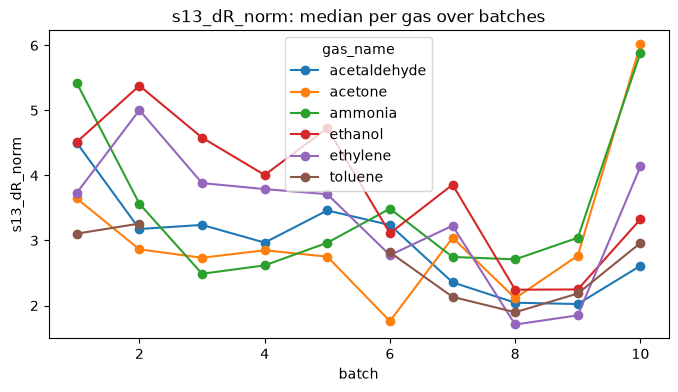

In [3]:
import matplotlib.pyplot as plt
feat = "s13_dR_norm"
med = data.groupby(["batch", "gas_name"])[feat].median().unstack()
med.plot(marker="o", figsize=(8, 4), title=f"{feat}: median per gas over batches")
plt.ylabel(feat); plt.show()

<Axes: xlabel='x', ylabel='y'>

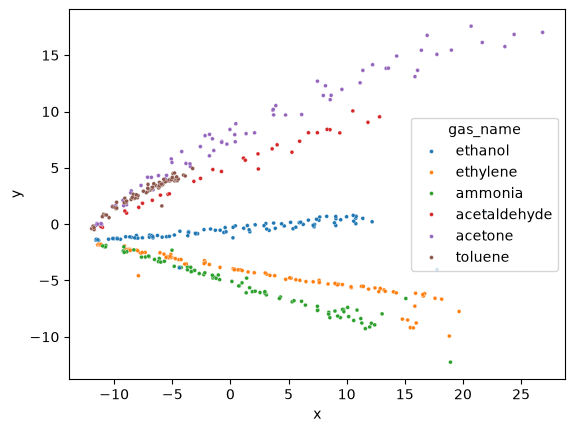

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns

feature_cols = list(data.filter(regex=r"^s\d+_").columns)
#slog = lambda a: np.sign(a) * np.log1p(np.abs(a))

def pca_batch(b):
    d = data[data["batch"] == b]
    Z = StandardScaler().fit_transform((d[feature_cols].to_numpy()))
    xy = PCA(n_components=2).fit_transform(Z)
    return d.assign(x=xy[:, 0], y=xy[:, 1])[["x", "y", "gas_name", "batch"]]

pca_df = pca_batch(1)
sns.scatterplot(data=pca_df, x="x", y="y", hue="gas_name", s=8)